In [33]:
# Importamos las librerías necesarias para el trabajo
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.datasets import load_digits, make_blobs
from sklearn.neighbors import KNeighborsClassifier #C.ML (Vecinos cercanos)
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans

In [34]:
# Cargamos el dataset y normalizamos los datos antes de entrenar
digits= load_digits()
x= digits.data/255 #NORMALIZAMOS LOS DATOS
y= digits.target
print(x.shape)
print(y.shape)

(1797, 64)
(1797,)


In [35]:
# Dividimos los datos en entrenamiento y prueba
x_train, x_test, y_train, y_test= train_test_split(x,y,test_size=0.2, random_state=42)

Text(0.5, 1.0, '3')

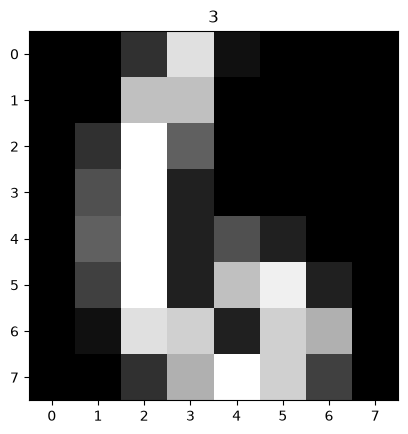

In [36]:
# Mostramos una imagen de entrenamiento en escala de grises
plt.imshow(x_train[0].reshape(8,8), cmap='gray')
plt.title(y_train[3])

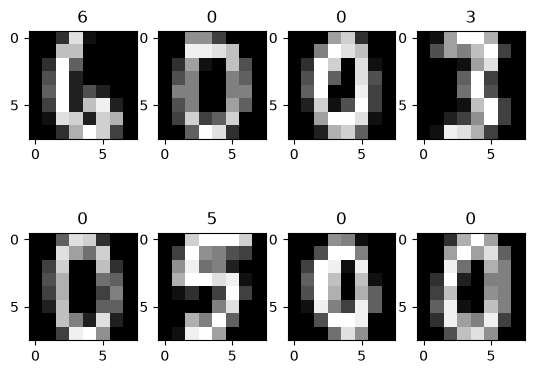

In [37]:
# Mostramos las primeras 8 imágenes de entrenamiento con su número
for i in range (8):
    plt.subplot(2,4,i+1)
    plt.imshow(x_train[i].reshape(8,8), cmap='gray')
    plt.title(y_train[i])

In [38]:
# Convertimos los datos en imágenes de 8x8 en escala de grises para la CNN
x_train_img= x_train.reshape(-1,8,8,1) #imagenes de 8x8 en escala de grises (1 canal)
x_test_img= x_test.reshape(-1,8,8,1)
print(x_train_img.shape)
print(x_test_img.shape)

(1437, 8, 8, 1)
(360, 8, 8, 1)


(8, 48)


Text(0.5, 1.0, 'Formulario con 6 digitos')

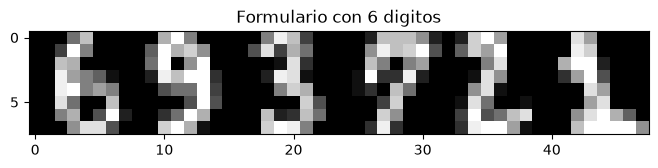

In [39]:
# Unimos 6 dígitos para que parezcan una fila de un formulario
filas= []
for fila in range(8):
    nueva_fila= []
    for i in range(6):
        nueva_fila= nueva_fila + list(x_test[i].reshape(8,8)[fila]) #juntamos la misma fila de los 6 digitos
    filas.append(nueva_fila)
formulario= np.array(filas)
print(formulario.shape)
plt.figure(figsize=(8,2))
plt.imshow(formulario, cmap='gray')
plt.title('Formulario con 6 digitos')

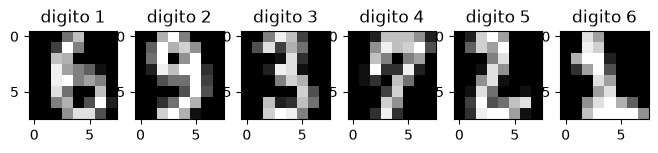

In [40]:
# Separamos los números del formulario que se juntaron anteriormente
digitos= []
for i in range(6):
    digitos.append(formulario[:, i*8:(i+1)*8]) #cortamos cada digito de 8 columnas
plt.figure(figsize=(8,2))
for i in range(6):
    plt.subplot(1,6,i+1)
    plt.imshow(digitos[i], cmap='gray')
    plt.title('digito '+str(i+1))

In [41]:
# Creamos la primera red neuronal densa (perceptrón multicapa) con TensorFlow para clasificar los dígitos
model= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(64,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,570 (25.66 KB)

 Trainable params: 6,570 (25.66 KB)

 Non-trainable params: 0 (0.00 B)

In [42]:
# Con model.fit entrenamos la red neuronal con una cantidad adecuada de épocas, sin abusar de ellas
model.fit(x_train, y_train, epochs=20)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.1872 - loss: 2.2840
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.3827 - loss: 2.2115
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.5449 - loss: 2.0493
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6333 - loss: 1.7773
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7300 - loss: 1.4453
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.7898 - loss: 1.1425
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8149 - loss: 0.9242
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8399 - loss: 0.7781
Epoch 9/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8553 - loss: 0.6760
Epoch 10/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8636 - loss: 0.5998
Epoch 11/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8713 - loss: 0.5394
Epoch 12/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8824 - l

In [43]:
# Aquí hacemos la predicción con los datos de prueba y la comparamos con los números reales
y_pred= model.predict(x_test)
print(y_pred.argmax(1))
print(y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
[6 9 3 7 2 1 5 2 5 2 1 4 4 0 4 2 3 7 8 8 4 3 9 7 5 6 3 5 6 3 4 9 2 4 4 6 9
 4 7 6 6 9 1 3 6 1 3 0 6 5 5 1 2 5 6 0 3 0 0 1 5 4 5 2 4 5 7 0 7 5 9 9 5 4
 7 0 4 5 5 9 9 0 2 3 8 0 6 4 4 9 1 2 1 3 9 2 9 4 4 4 4 3 5 3 1 3 5 1 4 2 7
 7 4 4 1 9 2 7 9 7 2 6 9 4 6 7 2 7 5 8 7 5 7 9 0 6 6 4 2 8 0 9 4 6 9 9 6 9
 0 5 5 6 6 0 6 4 2 9 3 8 7 2 9 0 4 5 2 6 5 7 9 8 4 2 1 3 7 7 2 2 3 9 8 0 3
 2 2 5 6 9 9 4 1 5 4 2 3 6 4 8 5 9 5 7 1 9 4 8 1 5 4 4 9 6 1 8 6 0 4 5 2 7
 1 6 4 5 6 0 3 2 3 6 7 9 9 1 4 7 6 5 2 5 5 1 0 1 8 8 7 5 7 6 2 2 2 3 4 8 8
 3 6 0 8 7 7 0 1 0 4 5 1 5 3 6 0 4 1 0 0 3 6 5 9 7 3 5 5 9 9 8 5 3 3 1 0 5
 8 3 4 0 2 4 6 4 3 4 5 0 5 2 1 3 1 4 1 1 7 0 4 5 2 1 2 8 7 0 6 4 8 8 5 1 8
 4 5 8 7 9 8 8 0 6 2 0 7 9 1 9 5 2 7 7 9 8 7 4 3 8 3 5]
[6 9 3 7 2 1 5 2 5 2 1 9 4 0 4 2 3 7 8 8 4 3 9 7 5 6 3 5 6 3 4 9 1 4 4 6 9
 4 7 6 6 9 1 3 6 1 3 0 6 5 5 1 9 5 6 0 9 0 0 1 0 4 5 2 4 5 7 0 7 5 9 5 5 4
 7 0 4 5 5 9 9 0 2 3 8 0 6 4 4 9 1 2 8 3 5 2 9 0 4 4 4 3 5 3 1 3 5 9 4 2 7
 7 4

In [44]:
# Calculamos el accuracy y el reporte de clasificación de la red densa
acc_densa= accuracy_score(y_test, y_pred.argmax(1))
print(acc_densa)
print(classification_report(y_test, y_pred.argmax(1)))

0.9055555555555556
              precision    recall  f1-score   support

           0       0.97      0.91      0.94        33
           1       0.77      0.86      0.81        28
           2       0.86      0.94      0.90        33
           3       0.97      0.91      0.94        34
           4       0.94      0.98      0.96        46
           5       0.91      0.91      0.91        47
           6       0.97      0.97      0.97        35
           7       0.94      0.97      0.96        34
           8       0.89      0.80      0.84        30
           9       0.82      0.78      0.79        40

    accuracy                           0.91       360
   macro avg       0.90      0.90      0.90       360
weighted avg       0.91      0.91      0.91       360



In [45]:
# Definimos la segunda red neuronal, esta es una red convolucional (CNN)
model_cnn= tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(8,8,1)),
    tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'), #DEVUELVE UN MAPA DE CARACTERÍSTICAS
    tf.keras.layers.MaxPooling2D(), #reducir el mapa de características
    tf.keras.layers.Conv2D(64, 3, activation='relu', padding='same'),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])
model_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model_cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 32)       │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 4, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 2, 2, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,002 (207.04 KB)

 Trainable params: 53,002 (207.04 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
# Entrenamos la CNN y revisamos con datos de validación si sus predicciones son correctas
historial= model_cnn.fit(x_train_img, y_train, epochs=20, validation_split=0.2) #20% para validacion

Epoch 1/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.1375 - loss: 2.2929 - val_accuracy: 0.1840 - val_loss: 2.2765
Epoch 2/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.2576 - loss: 2.2065 - val_accuracy: 0.3576 - val_loss: 2.0932
Epoch 3/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6040 - loss: 1.7863 - val_accuracy: 0.6875 - val_loss: 1.4406
Epoch 4/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7702 - loss: 1.0755 - val_accuracy: 0.8056 - val_loss: 0.8643
Epoch 5/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8181 - loss: 0.6838 - val_accuracy: 0.8264 - val_loss: 0.6655
Epoch 6/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8520 - loss: 0.5217 - val_accuracy: 0.8542 - val_loss: 0.5481
Epoch 7/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8625 - loss: 0.4380 - val_accuracy: 0.8576 - val_loss: 0.4871
Epoch 8/20
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8869 - loss: 0.3863 - val_accuracy: 0.8611 - val_loss

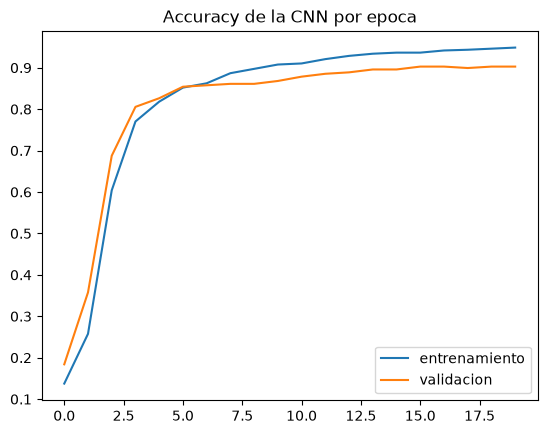

In [47]:
# En esta parte graficamos el accuracy de entrenamiento y validación para ver cómo aprendió la CNN en cada época
plt.plot(historial.history['accuracy'], label='entrenamiento')
plt.plot(historial.history['val_accuracy'], label='validacion')
plt.title('Accuracy de la CNN por epoca')
plt.legend()

In [48]:
# Aquí probamos la CNN con 10 y 30 épocas para comparar su accuracy y elegir la mejor (ajuste de hiperparámetros)
for epocas in [10, 30]: #ajuste de hiperparametros
    model_prueba= tf.keras.models.Sequential([
        tf.keras.layers.Input(shape=(8,8,1)),
        tf.keras.layers.Conv2D(32, 3, activation='relu', padding='same'),
        tf.keras.layers.MaxPooling2D(),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(10, activation='softmax')
    ])
    model_prueba.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    prueba= model_prueba.fit(x_train_img, y_train, epochs=epocas, validation_split=0.2, verbose=0)
    print('epocas', epocas, 'accuracy validacion', prueba.history['val_accuracy'][-1])

epocas 10 accuracy validacion 0.875
epocas 30 accuracy validacion 0.9444444179534912


In [49]:
# Hacemos la predicción con la CNN y la comparamos con los números reales
y_pred_cnn= model_cnn.predict(x_test_img).argmax(1)
print('Predicciones del modelo')
print(y_pred_cnn)
print('Etiquetas reales')
print(y_test)

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
Predicciones del modelo
[6 9 3 7 2 1 5 2 5 2 1 4 4 0 4 2 3 7 8 8 4 3 9 7 5 6 3 5 6 3 4 9 1 4 4 6 9
 4 7 6 6 9 1 3 6 1 3 0 6 5 5 1 9 5 6 0 9 0 0 1 0 4 5 2 4 5 7 0 7 5 9 5 5 4
 7 0 4 5 5 9 9 0 2 3 8 0 6 4 4 9 1 2 1 3 5 2 9 8 4 4 4 3 5 3 1 8 5 9 4 2 7
 7 4 4 1 9 2 7 8 7 2 6 9 4 0 7 2 7 5 8 7 5 7 9 0 6 6 4 2 8 0 9 4 6 9 9 6 9
 0 1 5 6 6 0 6 4 3 9 3 9 7 2 9 0 4 5 3 6 5 7 8 8 4 2 1 3 7 7 2 2 3 9 8 0 3
 2 2 5 6 9 9 4 1 2 4 2 3 6 4 8 5 9 5 7 1 9 4 8 1 5 4 4 9 6 1 8 6 0 4 5 2 7
 4 6 4 5 6 0 3 2 3 6 7 9 5 1 4 7 6 5 1 5 5 1 6 2 8 8 9 5 7 6 2 2 2 3 4 8 8
 3 6 0 8 7 7 0 1 0 4 5 1 5 3 6 0 4 1 0 0 3 6 5 9 7 3 5 5 9 9 4 5 3 3 2 0 5
 1 3 4 0 2 4 6 4 3 4 5 0 5 2 1 3 1 4 1 1 7 0 1 5 2 1 1 8 7 0 6 4 8 1 5 1 1
 4 5 8 7 9 8 5 0 6 2 0 7 9 1 9 5 2 7 7 9 8 7 4 3 8 3 5]
Etiquetas reales
[6 9 3 7 2 1 5 2 5 2 1 9 4 0 4 2 3 7 8 8 4 3 9 7 5 6 3 5 6 3 4 9 1 4 4 6 9
 4 7 6 6 9 1 3 6 1 3 0 6 5 5 1 9 5 6 0 9 0 0 1 0 4 5 2 4 5 7 0 7 5 9 5 5 4
 7 0 4 5 5 9 9 0 2 3 8 0 6 4 4 9 1 2 8 

In [50]:
# Calculamos el accuracy y el reporte de clasificación de la CNN
acc_cnn= accuracy_score(y_test, y_pred_cnn)
print(acc_cnn)
print(classification_report(y_test, y_pred_cnn))

0.9388888888888889
              precision    recall  f1-score   support

           0       1.00      0.97      0.98        33
           1       0.74      0.93      0.83        28
           2       0.97      0.97      0.97        33
           3       1.00      0.94      0.97        34
           4       0.96      1.00      0.98        46
           5       0.96      0.98      0.97        47
           6       1.00      1.00      1.00        35
           7       0.97      0.97      0.97        34
           8       0.84      0.70      0.76        30
           9       0.92      0.88      0.90        40

    accuracy                           0.94       360
   macro avg       0.94      0.93      0.93       360
weighted avg       0.94      0.94      0.94       360



Matriz de Confusión
[[32  0  0  0  0  0  0  0  1  0]
 [ 0 26  0  0  0  0  0  0  0  2]
 [ 0  1 32  0  0  0  0  0  0  0]
 [ 0  1  0 32  0  0  0  0  1  0]
 [ 0  0  0  0 46  0  0  0  0  0]
 [ 0  0  1  0  0 46  0  0  0  0]
 [ 0  0  0  0  0  0 35  0  0  0]
 [ 0  0  0  0  0  0  0 33  0  1]
 [ 0  7  0  0  1  1  0  0 21  0]
 [ 0  0  0  0  1  1  0  1  2 35]]


Text(0.5, 1.0, 'Matriz de confusion CNN')

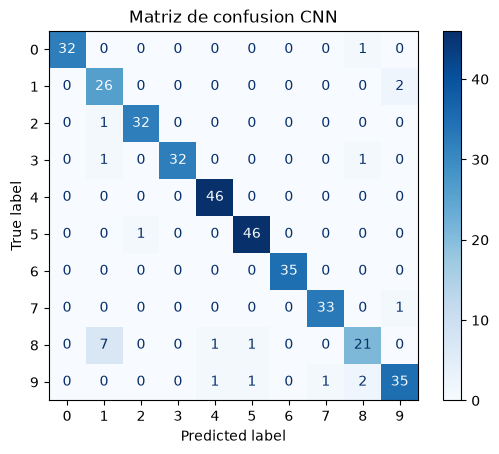

In [51]:
# Creamos la matriz de confusión de la CNN para ver qué dígitos confunde
print('Matriz de Confusión')
matriz= confusion_matrix(y_test, y_pred_cnn)
print(matriz)
ConfusionMatrixDisplay(matriz).plot(cmap='Blues')
plt.title('Matriz de confusion CNN')

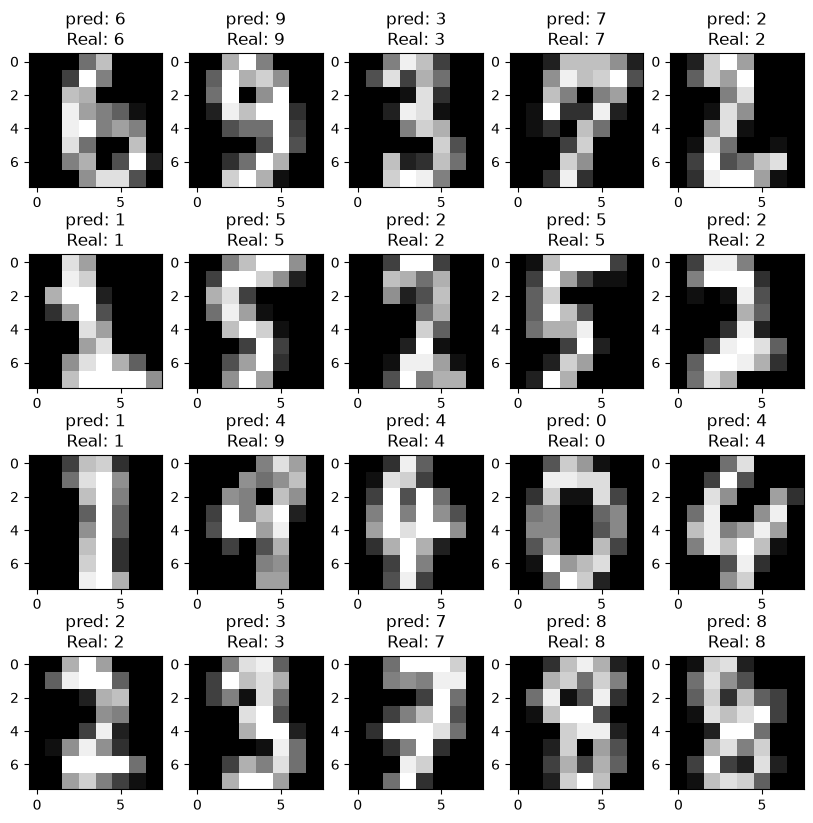

In [52]:
# Mostramos 20 imágenes con lo que predijo la CNN y el número real para ver si acertó
plt.figure(figsize=(10,10))
for i in range(20):
 plt.subplot(4,5,i+1)
 plt.imshow(x_test[i].reshape(8,8), cmap='gray')
 plt.title('pred: '+str(y_pred_cnn[i])+'\nReal: '+str(y_test[i]))

In [53]:
# La CNN lee los dígitos del formulario y verificamos si las predicciones están bien
pred_formulario= model_cnn.predict(np.array(digitos).reshape(-1,8,8,1)).argmax(1)
print('Digitos leidos del formulario', pred_formulario)
print('Digitos reales', y_test[:6])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
Digitos leidos del formulario [6 9 3 7 2 1]
Digitos reales [6 9 3 7 2 1]


In [54]:
# Entrenamos el modelo KNN y mostramos el accuracy y otros datos obtenidos de la predicción
model_knn= KNeighborsClassifier()
model_knn.fit(x_train, y_train)
y_pred_knn= model_knn.predict(x_test)
acc_knn= accuracy_score(y_test, y_pred_knn)
print(acc_knn)
print(classification_report(y_test, y_pred_knn))

0.9861111111111112
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       0.98      1.00      0.99        46
           5       0.98      0.96      0.97        47
           6       0.97      1.00      0.99        35
           7       1.00      0.97      0.99        34
           8       1.00      1.00      1.00        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [55]:
# Aquí hacemos la validación cruzada con KNN probando distintos valores de k para elegir el mejor
for k in [1, 3, 5, 7]: #validacion cruzada con 5 partes
    puntajes= cross_val_score(KNeighborsClassifier(n_neighbors=k), x, y, cv=5)
    print('k =', k, 'accuracy promedio', puntajes.mean())

k = 1 accuracy promedio 0.9643933766635715
k = 3 accuracy promedio 0.966621788919839
k = 5 accuracy promedio 0.9627282575054161
k = 7 accuracy promedio 0.9599458372021046


In [56]:
# Entrenamos el modelo SVM y mostramos el accuracy y otros datos obtenidos de la predicción
model_svm= SVC()
model_svm.fit(x_train, y_train)
y_pred_svm= model_svm.predict(x_test)
acc_svm= accuracy_score(y_test, y_pred_svm)
print(acc_svm)
print(classification_report(y_test, y_pred_svm))

0.9861111111111112
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      1.00      1.00        28
           2       1.00      1.00      1.00        33
           3       1.00      1.00      1.00        34
           4       1.00      1.00      1.00        46
           5       0.98      0.98      0.98        47
           6       0.97      1.00      0.99        35
           7       0.97      0.97      0.97        34
           8       1.00      0.97      0.98        30
           9       0.95      0.95      0.95        40

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



In [57]:
# Entrenamos la Regresión Logística, predecimos y calculamos el accuracy
model_log= LogisticRegression()
model_log.fit(x_train, y_train)
y_pred_log= model_log.predict(x_test)
acc_log= accuracy_score(y_test, y_pred_log)
print(acc_log)
print(classification_report(y_test, y_pred_log))

0.8944444444444445
              precision    recall  f1-score   support

           0       0.97      1.00      0.99        33
           1       0.70      0.82      0.75        28
           2       0.91      0.91      0.91        33
           3       0.97      0.97      0.97        34
           4       0.98      0.91      0.94        46
           5       0.95      0.83      0.89        47
           6       0.97      0.97      0.97        35
           7       0.81      1.00      0.89        34
           8       1.00      0.67      0.80        30
           9       0.76      0.85      0.80        40

    accuracy                           0.89       360
   macro avg       0.90      0.89      0.89       360
weighted avg       0.91      0.89      0.89       360



Red Densa 0.9055555555555556
CNN 0.9388888888888889
KNN 0.9861111111111112
SVM 0.9861111111111112
Reg. Logistica 0.8944444444444445


(0.0, 1.0)

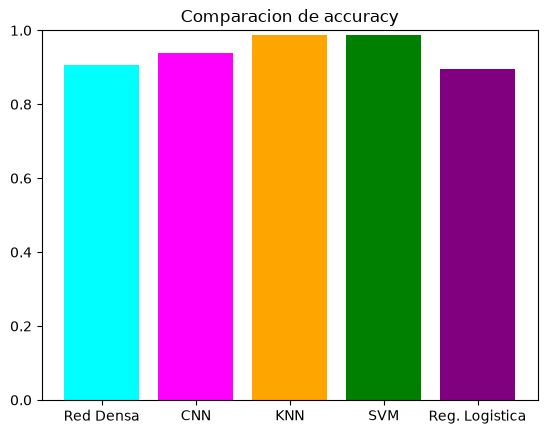

In [58]:
# Mostramos en un gráfico la comparación de los 5 modelos que se usaron para ver cuál sería la mejor opción
modelos= ['Red Densa','CNN','KNN','SVM','Reg. Logistica']
resultados= [acc_densa, acc_cnn, acc_knn, acc_svm, acc_log]
for i in range(5):
    print(modelos[i], resultados[i])
plt.bar(modelos, resultados, color=['cyan','magenta','orange','green','purple'])
plt.title('Comparacion de accuracy')
plt.ylim(0,1)

In [59]:
# Usamos datos creados (ficticios) para ver si la Regresión Lineal predice bien
x_reg=np.array([[1,2],
            [2,4],
            [3,6],
            [4,8],
            [5,10]]) #datos ficticios
y_reg=np.array([3,6,9,12,15])
model_reg = LinearRegression()
model_reg.fit(x_reg,y_reg)
predict= model_reg.predict(np.array([[10,20],[7,14]]))
print(predict)

[30. 21.]


Text(0.5, 1.0, 'K-Means con datos ficticios')

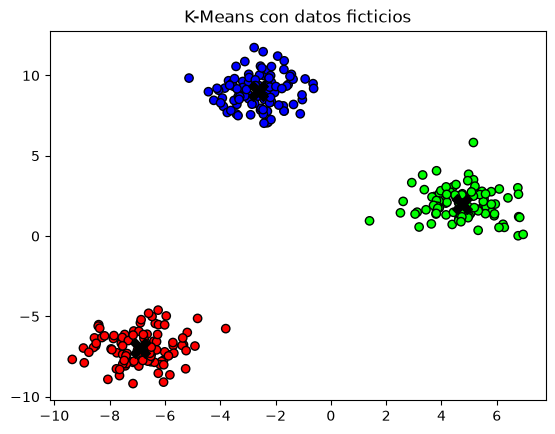

In [60]:
# Creamos datos ficticios y los agrupamos con K-Means en 3 grupos, sin decirle las respuestas (aprendizaje no supervisado)
# Luego los graficamos para ver cada grupo de un color y su punto medio (centro) marcado con una X
x_fic, y_fic= make_blobs(n_samples=300, centers=3, random_state=42) #datos ficticios
kmeans= KMeans(n_clusters=3, random_state=42)
grupos= kmeans.fit_predict(x_fic)
plt.scatter(x_fic[:,0], x_fic[:,1], c=grupos, cmap='brg', edgecolor='k')
plt.scatter(kmeans.cluster_centers_[:,0], kmeans.cluster_centers_[:,1], color='black', marker='X', s=200)
plt.title('K-Means con datos ficticios')